In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils.post_process import merge_bursts
from seasonal_burst.exhaustive_search import exhaustive_search
import utils_notebook as ub

from matplotlib.colors import BoundaryNorm


In [17]:
df = pd.read_csv("../Data/power/consommation-quotidienne-brute.csv", sep =";")
df['year'] = pd.DatetimeIndex(df['Date - Heure']).year
df['month'] = pd.DatetimeIndex(df['Date - Heure']).month
df['day'] = pd.DatetimeIndex(df['Date - Heure']).day
df = df[~((df.month == 2) & (df.day == 29))]
df = df[((df.year >= 2012) & (df.year <= 2023))]
n_year = 12
len_year = 365*24*2

In [18]:
df.head(5)

,Date - Heure,Date,Heure,Consommation brute gaz (MW PCS 0°C) - GRTgaz,Statut - GRTgaz,Consommation brute gaz (MW PCS 0°C) - Teréga,Statut - Teréga,Consommation brute gaz totale (MW PCS 0°C),Consommation brute électricité (MW) - RTE,Statut - RTE,Consommation brute totale (MW),year,month,day
14638,2023-12-31T23:30:00+00:00,01/01/2024,00:30,NaN,NaN,NaN,NaN,NaN,52667,Consolidé,NaN,2023,12,31
14639,2023-12-31T23:00:00+00:00,01/01/2024,00:00,40251.0,Définitif,3039.0,Définitif,43290.0,54537,Consolidé,97827.0,2023,12,31
14640,2023-12-31T22:30:00+00:00,31/12/2023,23:30,NaN,NaN,NaN,NaN,NaN,55306,Consolidé,NaN,2023,12,31
14641,2023-12-31T22:00:00+00:00,31/12/2023,23:00,40781.0,Meilleur Statut,3016.0,Définitif,43797.0,55335,Consolidé,99132.0,2023,12,31
14642,2023-12-31T21:30:00+00:00,31/12/2023,22:30,NaN,NaN,NaN,NaN,NaN,55629,Consolidé,NaN,2023,12,31


In [19]:
df.tail(5)

,Date - Heure,Date,Heure,Consommation brute gaz (MW PCS 0°C) - GRTgaz,Statut - GRTgaz,Consommation brute gaz (MW PCS 0°C) - Teréga,Statut - Teréga,Consommation brute gaz totale (MW PCS 0°C),Consommation brute électricité (MW) - RTE,Statut - RTE,Consommation brute totale (MW),year,month,day
225017,2012-01-01T02:00:00+00:00,01/01/2012,03:00,52836.0,Définitif,3212.0,Définitif,56048.0,52496,Définitif,108544.0,2012,1,1
225018,2012-01-01T01:30:00+00:00,01/01/2012,02:30,NaN,NaN,NaN,NaN,NaN,54911,Définitif,NaN,2012,1,1
225019,2012-01-01T01:00:00+00:00,01/01/2012,02:00,52251.0,Définitif,3214.0,Définitif,55465.0,55531,Définitif,110996.0,2012,1,1
225020,2012-01-01T00:30:00+00:00,01/01/2012,01:30,NaN,NaN,NaN,NaN,NaN,56075,Définitif,NaN,2012,1,1
225021,2012-01-01T00:00:00+00:00,01/01/2012,01:00,52236.0,Définitif,3208.0,Définitif,55444.0,56230,Définitif,111674.0,2012,1,1


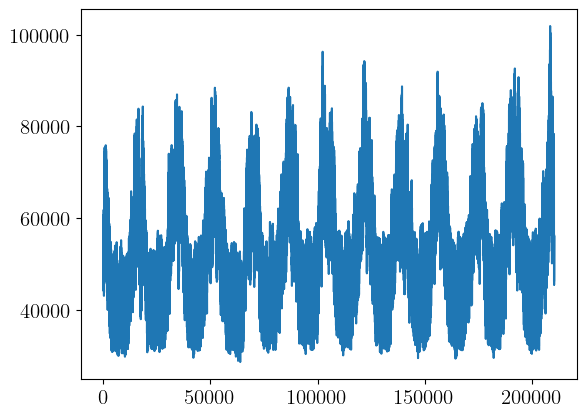

In [20]:
ts = np.array(df['Consommation brute électricité (MW) - RTE']).astype(np.float64)
yearly_ts = np.copy(ts.reshape((12, 365*24*2)))
mean = np.mean(yearly_ts, axis=0)

plt.plot(ts)

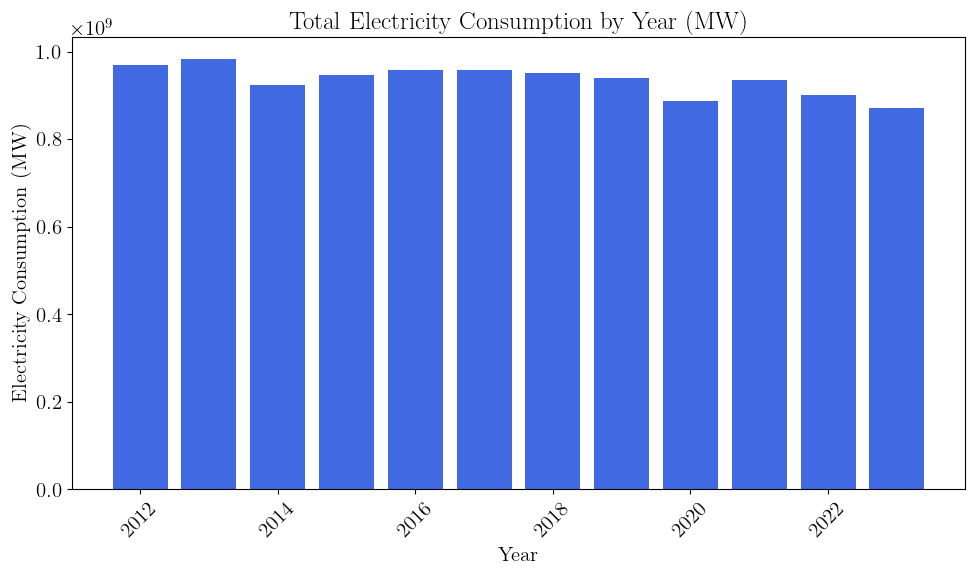

In [21]:
grouped_df = df[['year', 'Consommation brute électricité (MW) - RTE']].groupby('year').sum()

plt.figure(figsize=(10, 6))
plt.bar(grouped_df.index, grouped_df['Consommation brute électricité (MW) - RTE'], color='royalblue')

plt.title('Total Electricity Consumption by Year (MW)')
plt.xlabel('Year')
plt.ylabel('Electricity Consumption (MW)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
%%time
bursts = exhaustive_search(ts, 12, 2.5, 365*24*2, 1, 7*24*2)
union_bursts = merge_bursts(bursts)

CPU times: user 974 ms, sys: 9.16 ms, total: 983 ms
Wall time: 970 ms


In [34]:
import time as time
times = []
for _ in range(100):
    start_time = time.time()
    bursts = exhaustive_search(ts, 12, 2.5, 365*24*2, 1, 7*24*2)
    union_bursts = merge_bursts(bursts)
    end_time = time.time()
    times.append(end_time - start_time)
print(f"Time: {np.mean(times):.3f} $\\pm$ {np.std(times):.3f} (s)") 

Time: 0.961 $\pm$ 0.004 (s)


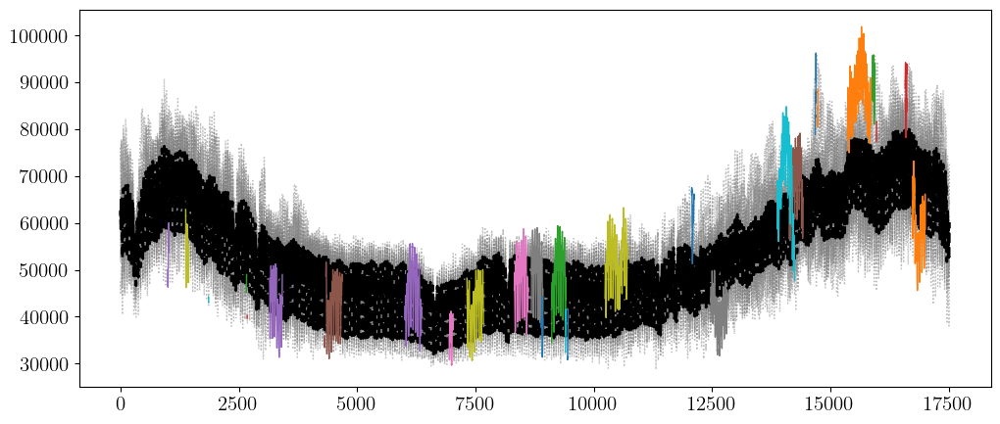

In [24]:
fig, ax = plt.subplots(figsize=(12, 5))


for year in range(n_year):
    ax.plot(yearly_ts[year, :], color='grey', linestyle=':', linewidth=1, alpha=0.5)
ax.plot(mean, color='black', linestyle='--', linewidth=2, label='Daily Average')

for (start, end, z) in union_bursts:
    length = end - start + 1
    i_start = start % len_year
    year = start // len_year
    xs = np.arange(i_start, i_start + length)

    ax.plot(xs, ts[start:start + length], linewidth=1, label=f"{2012 + year}")

plt.show()

In [25]:
ts_date = pd.date_range(start='2012-01-01', end='2023-12-31 23:59:59', freq='30min')
ts_date = ts_date[~((ts_date.month == 2) & (ts_date.day == 29))]

burst_df, yearly_sum = ub.compute_statistics(ts, ts_date, union_bursts, 365*24*2)

fig = ub.plot_bars(yearly_sum)
fig.show()

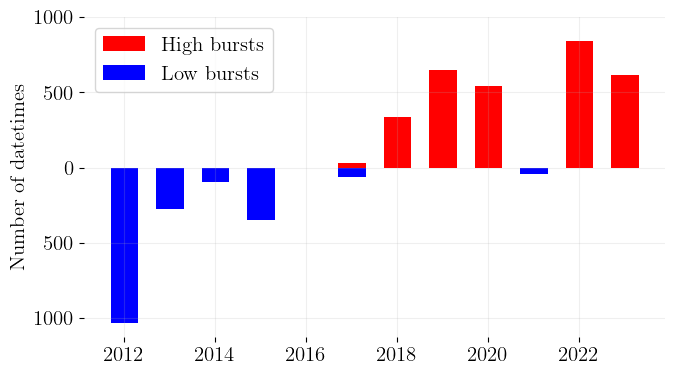

In [26]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Latin Modern Roman"],
})
plt.rcParams['font.size'] = 15
plt.figure(figsize=(7, 4)), plt.grid(alpha=0.2)
plt.bar(yearly_sum['year'], yearly_sum['hot'], width=0.6, color='red', label ='High bursts')
plt.bar(yearly_sum['year'], -yearly_sum['cold'], width=0.6, color='blue', label ='Low bursts')

ax = plt.gca()
custom_positions = [-1000, -500, 0, 500, 1000]  
custom_labels = [1000, 500, 0, 500, 1000]   
ax.set_yticks(custom_positions)         
ax.set_yticklabels(custom_labels)       

plt.ylabel('Number of datetimes')
for pos in ['right', 'top', 'bottom', 'left']: plt.gca().spines[pos].set_visible(False)
plt.legend()
plt.tight_layout()
plt.savefig("power_year.pdf", format="pdf", bbox_inches='tight')


plt.show()

In [27]:
import plotly.graph_objects as go


fig = go.Figure()

for year in range(n_year):
    fig.add_trace(go.Scatter(y=yearly_ts[year, :],
                             mode='lines',
                             line=dict(color='grey', dash='dot', width=1),
                             opacity=0.5
                             ,showlegend=False))
fig.add_trace(go.Scatter(y=mean,
                         mode='lines',
                         line=dict(color='black', dash='dash', width=2),
                         name='Daily Average'))

for (start, end, z) in union_bursts:
    length = end - start + 1
    i_start = start % len_year
    year = start // len_year
    xs = np.arange(i_start, i_start + length)

    fig.add_trace(go.Scatter(x=xs,
                             y=ts[start:start + length],
                             mode='lines',
                             line=dict(width=3),
                             name=f"{2012 + year}"))

fig.update_layout(title='Yearly Time Series with Bursts',
                  xaxis_title='Day of Year',
                  yaxis_title='Value',
                  height=500, width=1000)

fig.show()


In [28]:
z_per_day = ub.compute_daily_zscore(ts, n_year, len_year)  

Maximum: 2.9447880611107395, Minimum: -2.8220007438859


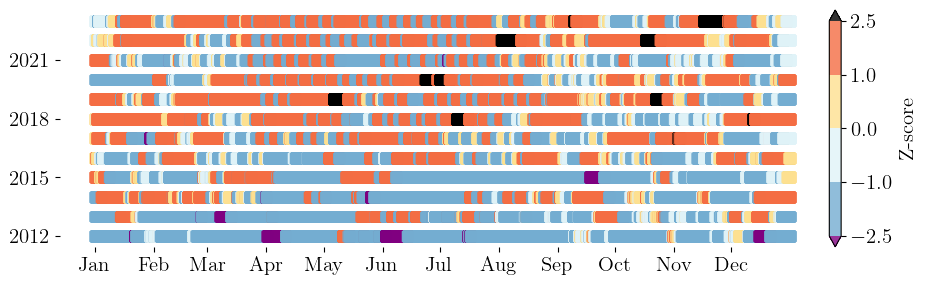

In [29]:
first_day_of_months = np.where(ts_date[:len_year].day == 1)[0][::48]
str_dates = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul",
             "Aug", "Sep", "Oct", "Nov", "Dec"]
min_year = 2012
max_year = 2023
all_max, all_min = max(z_per_day), min(z_per_day)
print(f"Maximum: {all_max}, Minimum: {all_min}")
first_year, last_year = ts_date[0].year, ts_date[-1].year
# Discrete colorbar
levels = [-2.5, -1, 0, 1, 2.5]
norm = BoundaryNorm(boundaries=levels, ncolors=256, extend='both')
x = np.arange(len_year)
cmap = plt.cm.RdYlBu_r
cmap.set_over("black")
cmap.set_under("purple")

plt.figure(figsize=(10,3.1))
for year in range(n_year):
    if max_year < year + first_year or year + first_year < min_year:
        continue
    plt.scatter(x, np.ones(len_year) * year + first_year, c=z_per_day[year * len_year:(year + 1) * len_year], 
                cmap=cmap, norm=norm, marker='s', s=50, alpha=0.8)

# Reduce padding of the colorbar
cbar = plt.colorbar(ticks=levels, pad=0.005)  # Reduced pad value

cbar.set_label('Z-score')
plt.xticks(first_day_of_months, str_dates)
plt.yticks([2012,2015,2018,2021], [2012,2015,2018,2021])

# Hide borders
for pos in ['right', 'top', 'bottom', 'left']:
    plt.gca().spines[pos].set_visible(False)


plt.tight_layout()
plt.rcParams['font.size'] = 15
plt.savefig("power_heatmap.pdf", format="pdf", bbox_inches='tight')

plt.show()

In [30]:
ts_g = np.array(df['Consommation brute gaz totale (MW PCS 0°C)']).astype(np.float64)[1::2]
yearly_tsg = np.copy(ts_g.reshape((12, 365*24)))
meang = np.mean(yearly_tsg, axis=0)

burstsg = exhaustive_search(ts_g, 12, 2.5, 365*24, 1, 7*24)
union_burstsg = merge_bursts(burstsg)

fig = go.Figure()
for year in range(n_year):
    fig.add_trace(go.Scatter(y=yearly_tsg[year, :],
                             mode='lines',
                             line=dict(color='grey', dash='dot', width=1),
                             opacity=0.5
                             ,showlegend=False))
fig.add_trace(go.Scatter(y=meang,
                         mode='lines',
                         line=dict(color='black', dash='dash', width=2),
                         name='Daily Average'))

for (start, end, z) in union_burstsg:
    length = end - start + 1
    i_start = start % (365*24)
    year = start // (365*24)
    xs = np.arange(i_start, i_start + length)

    fig.add_trace(go.Scatter(x=xs,
                             y=ts_g[start:start + length],
                             mode='lines',
                             line=dict(width=3),
                             name=f"{2012 + year}"))
fig.update_layout(title='Yearly Time Series with Bursts',
                  xaxis_title='Day of Year',
                  yaxis_title='Value',
                  height=500, width=1000)
fig.show()